# Stage 4: Data cleaning and data quality
Cleaning rules in a regulated model must be **documented, deterministic and reproducible**. This notebook:
1. Profiles missing values and checks whether *missingness itself* carries risk signal
2. Checks for duplicates at the correct grain of each table
3. Investigates outliers and anomaly codes (e.g. `DAYS_EMPLOYED = 365243`)
4. Fixes data types and impossible values (`credit_risk.cleaning`)
5. Validates the result against business rules

**What is *not* done here:** imputation, outlier capping and encoding. Those are *learned* from data, so they are
fitted inside the sklearn pipeline on the training split only (Stage 7). Doing them here, on the full data, is a
classic source of leakage.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from credit_risk.cleaning import (
    clean_application,
    duplicate_report,
    missing_report,
    missing_vs_target,
    numeric_columns,
    outlier_report,
    validate_application,
)
from credit_risk.config import get_paths, load_config
from credit_risk.data_loader import load_table
from credit_risk.viz import COLORS, savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()
ANOM = cfg["data"]["days_anomaly_value"]

app = load_table("application_train", cfg)
app_test = load_table("application_test", cfg)
print(app.shape, app_test.shape)

(307511, 122) (48744, 121)


## 1. Missing values

In [2]:
miss = missing_report(app)
print(f"{len(miss)} of {app.shape[1]} columns have missing values; {(miss['missing_pct'] > 50).sum()} are more than 50% empty.")
miss.head(20)

67 of 122 columns have missing values; 41 are more than 50% empty.


,missing_count,missing_pct,dtype
COMMONAREA_MEDI,214865,69.87,float32
COMMONAREA_MODE,214865,69.87,float32
COMMONAREA_AVG,214865,69.87,float32
NONLIVINGAPARTMENTS_MODE,213514,69.43,float32
NONLIVINGAPARTMENTS_MEDI,213514,69.43,float32
NONLIVINGAPARTMENTS_AVG,213514,69.43,float32
FONDKAPREMONT_MODE,210295,68.39,str
LIVINGAPARTMENTS_AVG,210199,68.35,float32
LIVINGAPARTMENTS_MEDI,210199,68.35,float32
LIVINGAPARTMENTS_MODE,210199,68.35,float32


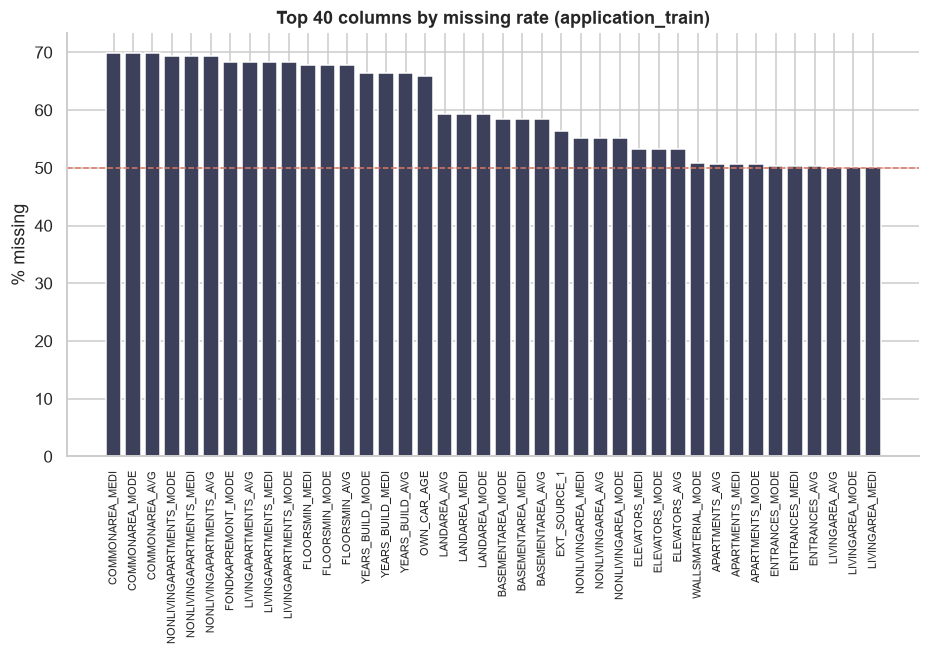

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
top = miss.head(40)
ax.bar(range(len(top)), top["missing_pct"], color=COLORS["neutral"])
ax.set_xticks(range(len(top)), top.index, rotation=90, fontsize=7)
ax.axhline(50, ls="--", color=COLORS["bad"], lw=1)
ax.set(ylabel="% missing", title="Top 40 columns by missing rate (application_train)")
savefig(fig, "cleaning_missing_rates")
plt.show()

**Pattern:** most of the >50% missing columns are building statistics (`*_AVG`, `*_MODE`, `*_MEDI`) collected only for
some housing types, plus `EXT_SOURCE_1` and `OWN_CAR_AGE` (missing = no car). These values aren't missing at random,
so we **don't drop them**:

In [4]:
mvt = missing_vs_target(app, min_missing_pct=5)
mvt.head(15)

,column,missing_pct,default_rate_missing,default_rate_present,lift_when_missing
55,AMT_REQ_CREDIT_BUREAU_QRT,13.5,10.34,7.72,1.34
51,AMT_REQ_CREDIT_BUREAU_HOUR,13.5,10.34,7.72,1.34
52,AMT_REQ_CREDIT_BUREAU_DAY,13.5,10.34,7.72,1.34
53,AMT_REQ_CREDIT_BUREAU_WEEK,13.5,10.34,7.72,1.34
54,AMT_REQ_CREDIT_BUREAU_MON,13.5,10.34,7.72,1.34
56,AMT_REQ_CREDIT_BUREAU_YEAR,13.5,10.34,7.72,1.34
11,FLOORSMAX_AVG,49.8,9.19,6.97,1.32
20,YEARS_BEGINEXPLUATATION_MODE,48.8,9.20,6.99,1.32
6,YEARS_BEGINEXPLUATATION_AVG,48.8,9.20,6.99,1.32
38,ENTRANCES_MEDI,50.3,9.18,6.95,1.32


When `lift_when_missing` is far from 1, missingness itself predicts risk. Our strategy:
- **Tree models (XGBoost, LightGBM):** keep `NaN`. They learn the best direction for missing values at each split.
- **Logistic regression:** median imputation **plus a missing-indicator column**, fitted on train only.
- **Drop** only features that are almost entirely empty (>95%) in the training split (Stage 7).

## 2. Duplicates
Check duplicates at each table's real primary key, not only exact row duplicates.

In [5]:
other = {name: load_table(name, cfg) for name in ["bureau", "previous_application"]}
dup = duplicate_report(
    {"application_train": app, "application_test": app_test, **other},
    keys={"application_train": ["SK_ID_CURR"], "application_test": ["SK_ID_CURR"], "bureau": ["SK_ID_BUREAU"], "previous_application": ["SK_ID_PREV"]},
)
display(dup)
overlap = np.intersect1d(app["SK_ID_CURR"], app_test["SK_ID_CURR"]).size
print(f"Applicants appearing in both train and test: {overlap}")
del other

,table,rows,exact_duplicate_rows,primary_key,duplicate_keys
0,application_train,307511,0,SK_ID_CURR,0
1,application_test,48744,0,SK_ID_CURR,0
2,bureau,1716428,0,SK_ID_BUREAU,0
3,previous_application,1670214,0,SK_ID_PREV,0


Applicants appearing in both train and test: 0


## 3. Anomalies and outliers
### 3.1 The `DAYS_EMPLOYED = 365243` placeholder
365,243 days is about 1,000 years. It's a system code, not a real value. Who has it?

In [6]:
anom = app["DAYS_EMPLOYED"] == ANOM
print(f"{anom.mean():.1%} of applicants have the placeholder")
display(app.loc[anom, "NAME_INCOME_TYPE"].value_counts().to_frame("applicants"))
display(pd.DataFrame({
    "default_rate_pct": [100 * app.loc[anom, "TARGET"].mean(), 100 * app.loc[~anom, "TARGET"].mean()]
}, index=["placeholder (not employed)", "employed"]).round(2))

18.0% of applicants have the placeholder


,applicants
NAME_INCOME_TYPE,
Pensioner,55352
Unemployed,22


,default_rate_pct
placeholder (not employed),5.40
employed,8.66


Almost all are pensioners, and their default rate differs from everyone else's. **Decision:** create
`FLAG_DAYS_EMPLOYED_ANOM` to keep that information, and set the value itself to missing. If we left it in, a linear
model would read it as "employed for 1,000 years".

In [7]:
num_cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "DAYS_BIRTH",
            "DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "CNT_CHILDREN", "CNT_FAM_MEMBERS", "OWN_CAR_AGE"]
outliers = outlier_report(app.assign(DAYS_EMPLOYED=app["DAYS_EMPLOYED"].where(~anom)), num_cols + ["DAYS_EMPLOYED"])
outliers.round(1)

,column,p1,median,p99,max,lower_fence,upper_fence,outliers,outlier_pct
0,AMT_INCOME_TOTAL,45000.0,147150.0,472500.0,117000000.0,-157500.0,472500.0,3014,1.0
1,AMT_CREDIT,76410.0,513531.0,1854000.0,4050000.0,-1345950.0,2424600.0,444,0.1
2,AMT_ANNUITY,6182.9,24903.0,70006.5,258025.5,-37692.0,88812.0,1024,0.3
3,AMT_GOODS_PRICE,67500.0,450000.0,1800000.0,4050000.0,-1084500.0,2002500.0,1090,0.4
4,DAYS_BIRTH,-24419.0,-15750.0,-8263.0,-7489.0,-41489.0,9394.0,0,0.0
5,DAYS_REGISTRATION,-13879.0,-4504.0,-50.0,0.0,-23888.0,14398.5,1,0.0
6,DAYS_ID_PUBLISH,-5447.0,-3254.0,-61.0,0.0,-12036.0,6017.0,0,0.0
7,CNT_CHILDREN,0.0,0.0,3.0,19.0,-3.0,4.0,126,0.0
8,CNT_FAM_MEMBERS,1.0,2.0,5.0,20.0,-1.0,6.0,121,0.0
9,OWN_CAR_AGE,0.0,9.0,64.0,91.0,-25.0,45.0,3375,3.2


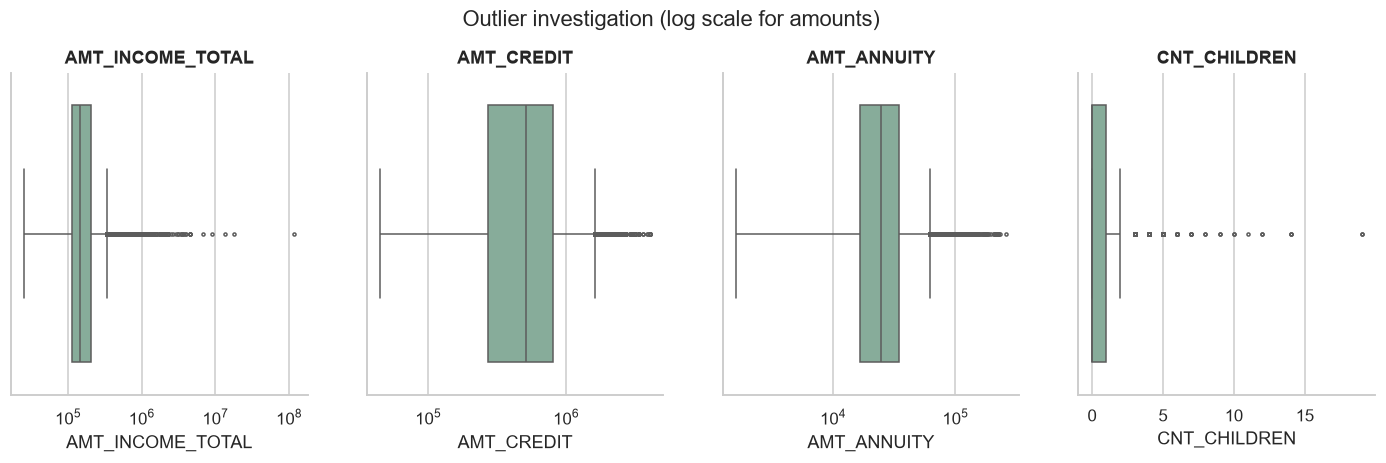

        SK_ID_CURR  AMT_INCOME_TOTAL  AMT_CREDIT      NAME_INCOME_TYPE  TARGET
12840       114967       117000000.0    562491.0               Working       1
203693      336147        18000090.0    675000.0  Commercial associate       0
246858      385674        13500000.0   1400503.5  Commercial associate       0
77768       190160         9000000.0   1431531.0               Working       0
131127      252084         6750000.0    790830.0               Working       0


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "CNT_CHILDREN"]):
    sns.boxplot(x=app[col], ax=ax, color=COLORS["accent"], fliersize=2)
    ax.set_title(col)
    ax.set_xscale("log" if col.startswith("AMT") else "linear")
fig.suptitle("Outlier investigation (log scale for amounts)", y=1.03)
savefig(fig, "cleaning_outliers")
plt.show()
print(app.nlargest(5, "AMT_INCOME_TOTAL")[["SK_ID_CURR", "AMT_INCOME_TOTAL", "AMT_CREDIT", "NAME_INCOME_TYPE", "TARGET"]])

**Outlier decisions**
| Column | Finding | Treatment |
|---|---|---|
| `AMT_INCOME_TOTAL` | A handful of extreme incomes (on the full data one applicant reports ~117M) | Keep the rows. Tree models are insensitive to them; for logistic regression we **winsorise at the 0.5/99.5 percentiles learned on train** |
| `AMT_CREDIT`, `AMT_ANNUITY` | Long right tail, but plausible | Keep; ratios (credit/income) are more informative |
| `CNT_CHILDREN` | Rare values above 10 | Keep; tree splits handle them |
| `DAYS_EMPLOYED` | 365243 placeholder | Flag + set to missing |
| Placeholder categories | `CODE_GENDER = 'XNA'`, `NAME_FAMILY_STATUS = 'Unknown'`, `ORGANIZATION_TYPE = 'XNA'` | Missing / explicit "Not employed" |

Outliers are **not deleted**. In credit risk an unusual applicant is still an applicant the model must score, and
deleting them makes offline performance look better than production.

## 4. Apply the cleaning rules and fix data types

In [9]:
before = validate_application(app)
app_clean = clean_application(app, ANOM)
test_clean = clean_application(app_test, ANOM)
after = validate_application(app_clean)

checks = before[["check", "passed"]].merge(after[["check", "passed", "detail"]], on="check", how="outer", suffixes=("_before", "_after"))
checks

,check,passed_before,passed_after,detail
0,AMT_ANNUITY > 0,True,True,0 non-positive
1,AMT_CREDIT > 0,True,True,0 non-positive
2,AMT_GOODS_PRICE > 0,True,True,0 non-positive
3,AMT_INCOME_TOTAL > 0,True,True,0 non-positive
4,Annuity does not exceed credit amount,True,True,0 rows
5,Applicant age between 18 and 75,True,True,"min 20.5, max 69.1"
6,DAYS_EMPLOYED <= 0 (anomaly removed),False,True,0 positive values
7,"EXT_SOURCE_1 within [0, 1]",True,True,"min 0.015, max 0.963"
8,"EXT_SOURCE_2 within [0, 1]",True,True,"min 0.000, max 0.855"
9,"EXT_SOURCE_3 within [0, 1]",True,True,"min 0.001, max 0.896"


In [10]:
dtype_summary = pd.DataFrame({"before": app.dtypes.astype(str).value_counts(), "after": app_clean.dtypes.astype(str).value_counts()}).fillna(0).astype(int)
dtype_summary

,before,after
float32,65,67
float64,0,1
int16,2,2
int32,2,0
int64,0,1
int8,37,38
object,0,1
str,16,13


Remaining failed checks (if any) are documented, not silently fixed. For example, a few applications where the
annuity is larger than the credit amount may be real product types, so they stay in and are flagged for the business.

## 5. Save cleaned tables

In [11]:
app_clean.to_parquet(paths["interim_data"] / "application_train_clean.parquet", index=False)
test_clean.to_parquet(paths["interim_data"] / "application_test_clean.parquet", index=False)
quality = pd.concat([miss.assign(section="missing").reset_index(names="column"), after.assign(section="validation")], ignore_index=True)
quality.to_csv(paths["reports"] / "data_quality_report.csv", index=False)
print("Saved cleaned application tables to data/interim/ and the data-quality report to reports/")

Saved cleaned application tables to data/interim/ and the data-quality report to reports/
